[Ouvrir dans Colab](https://colab.research.google.com/github/moonlovist/EEEA-ML/blob/main/sessions/session02/lab/fr/01_Demonstrations_FR.ipynb)

# TP 02 · Expériences guidées
Ting Tan · EEEA

De la régression à la classification.

## Prise en main
Exécuter les cellules dans l’ordre avec **Maj+Entrée**. Aucun GPU ni clé API n’est nécessaire. Les données sont incluses ; aucun fichier de données à importer.

**Colab :** ouvrir [Colab](https://colab.research.google.com/), choisir **Fichier → Importer un notebook**, importer ce `.ipynb` et se connecter à un environnement Python. Enregistrer/télécharger le notebook avant de quitter.

**Jupyter local :** dans un terminal du dossier extrait :
```
python -m pip install -r requirements.txt
python -m notebook
```
Si Jupyter est déjà configuré, utiliser l’environnement habituel.

Exécuter les imports ci-dessous. Si les résultats deviennent incohérents, redémarrer le noyau/l’environnement et tout exécuter dans l’ordre. Lire les erreurs à partir de leur dernière ligne.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_curve, roc_auc_score, precision_recall_curve,
    average_precision_score
)
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11})

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    # Equivalent to 1 / (1 + exp(-z)), with stable evaluation.
    return np.exp(-np.logaddexp(0.0, -z))

def mean_bce(x, c, w, b):
    z = w * x + b
    return float(np.mean(np.logaddexp(0.0, z) - c * z))

print("Python / NumPy / Matplotlib / scikit-learn: OK")

Python / NumPy / Matplotlib / scikit-learn: OK


**Rappels Python :** `np.array` stocke un vecteur ; `*` multiplie terme à terme ; `np.mean` calcule une moyenne. `p >= 0.5` produit des booléens ; `np.sum(condition)` compte les valeurs `True`. Les indices commencent à 0.

`sigmoid` et `mean_bce` calculent de façon stable les formules du cours. Les logarithmes sont naturels.

## D1 · Une mise à jour linéaire
Reprendre les trois observations du cours. Repérer les opérations dans le code.
$$r_i=wx_i+b-y_i,\quad J=\frac{1}{2n}\sum_i r_i^2.$$
$$g_w=\frac1n\sum_i r_ix_i,\quad g_b=\frac1n\sum_i r_i.$$
Les gradients utilisent les **anciens** paramètres. La dernière affectation les met à jour simultanément.

In [2]:
x = np.array([1., 2., 3.])
y = np.array([12., 19., 32.])
w, b, eta = 10.0, 0.0, 0.1

prediction = w * x + b
residual = prediction - y
loss = np.mean(residual ** 2) / 2
dw = np.mean(residual * x)
db = np.mean(residual)
w_new, b_new = w - eta * dw, b - eta * db
new_loss = np.mean((w_new * x + b_new - y) ** 2) / 2

print("residual =", residual)
print("J =", loss, "| dw =", dw, "| db =", db)
print("w_new =", w_new, "| b_new =", b_new)
print("J_new =", new_loss)
assert np.allclose([dw, db, w_new, b_new, new_loss],
                   [-2, -1, 10.2, 0.1, 6.83 / 6])

residual = [-2.  1. -2.]
J = 1.5 | dw = -2.0 | db = -1.0
w_new = 10.2 | b_new = 0.1
J_new = 1.1383333333333343


**Vérifier :** résidus `[-2, 1, -2]`, gradients `(-2, -1)`, paramètres `(10.2, 0.1)`, nouvelle perte `1.1383333333`.

Exécuter le tracé. Les pointillés montrent les résidus initiaux. Pourquoi un gradient négatif augmente-t-il le paramètre ?

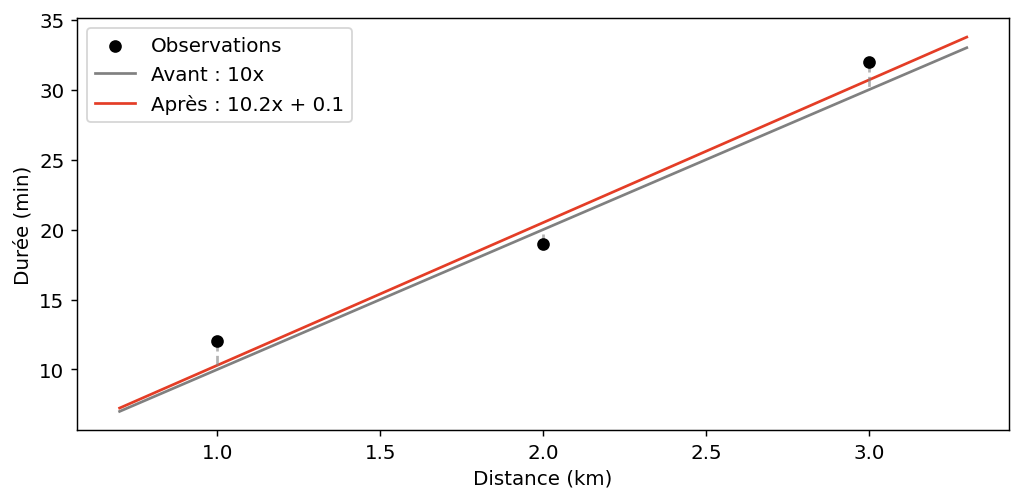

In [3]:
grid = np.linspace(0.7, 3.3, 100)
plt.scatter(x, y, color="black", label="Observations", zorder=3)
plt.plot(grid, 10 * grid, color="gray", label="Avant : 10x")
plt.plot(grid, w_new * grid + b_new, color="#e43d26",
         label="Après : 10.2x + 0.1")
for xi, yi, pi in zip(x, y, prediction):
    plt.plot([xi, xi], [yi, pi], "--", color="gray", alpha=0.6)
plt.xlabel("Distance (km)")
plt.ylabel("Durée (min)")
plt.legend()
plt.tight_layout()
plt.show()

## D2 · Entraîner un classifieur logistique
La classe vaut $c=1$ si la durée dépasse 30 minutes, sinon $c=0$.
$$p_i=\sigma(wx_i+b),\quad g_w=\frac1n\sum_i(p_i-c_i)x_i,\quad g_b=\frac1n\sum_i(p_i-c_i).$$
Partir de $w=b=0$ et effectuer un pas. L’objectif est l’**entropie croisée binaire moyenne**.

In [4]:
x_binary = np.arange(1., 7.)
duration = np.array([12., 19., 32., 29., 48., 57.])
c_binary = (duration > 30).astype(int)
w, b, eta = 0.0, 0.0, 0.1

p = sigmoid(w * x_binary + b)
dw = np.mean((p - c_binary) * x_binary)
db = np.mean(p - c_binary)
w_new, b_new = w - eta * dw, b - eta * db

print("c =", c_binary, "| p =", p)
print("dw =", dw, "| db =", db)
print("J_before =", mean_bce(x_binary, c_binary, w, b))
print("w_new =", w_new, "| b_new =", b_new)
print("J_after =", mean_bce(x_binary, c_binary, w_new, b_new))
assert np.allclose([dw, db, w_new, b_new], [-7/12, 0, 7/120, 0])
assert np.isclose(mean_bce(x_binary, c_binary, w_new, b_new),
                  0.6655477879161796)

c = [0 0 1 0 1 1] | p = [0.5 0.5 0.5 0.5 0.5 0.5]
dw = -0.5833333333333334 | db = 0.0
J_before = 0.6931471805599453
w_new = 0.05833333333333334 | b_new = 0.0
J_after = 0.6655477879161796


**Vérifier :** `dw = -7/12`, `db = 0`. La perte passe de `log(2) ≈ 0.693147` à `0.6655477879`.

Répéter la règle 5 000 fois. Le graphique de gauche montre l’optimisation ; celui de droite, les probabilités apprises.

w = 1.21344579, b = -4.24682298, BCE = 0.4129978434


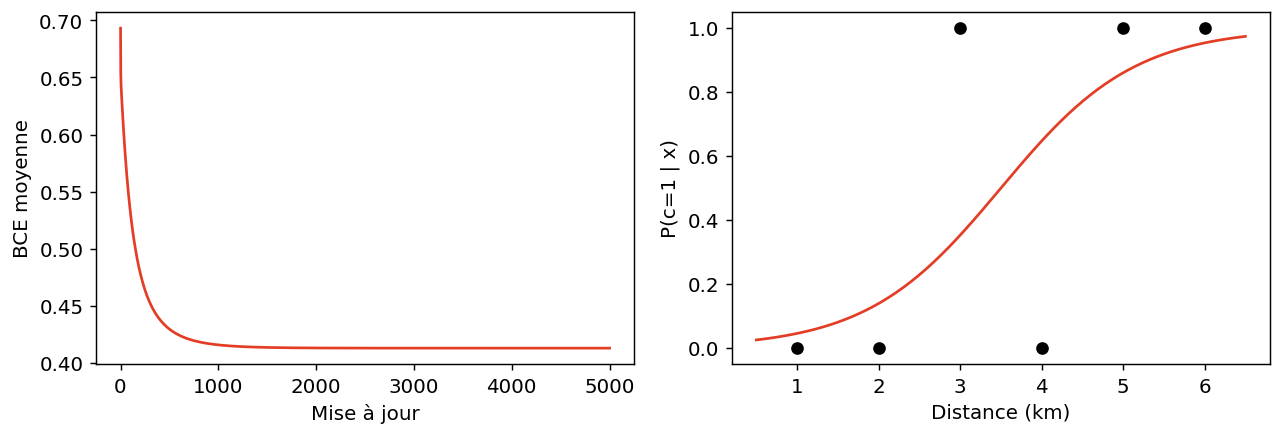

In [5]:
w, b = 0.0, 0.0
eta, updates = 0.1, 5000
losses = [mean_bce(x_binary, c_binary, w, b)]
for step in range(updates):
    p = sigmoid(w * x_binary + b)
    dw = np.mean((p - c_binary) * x_binary)
    db = np.mean(p - c_binary)
    w, b = w - eta * dw, b - eta * db
    losses.append(mean_bce(x_binary, c_binary, w, b))

print(f"w = {w:.8f}, b = {b:.8f}, BCE = {losses[-1]:.10f}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(losses, color="#e43d26")
axes[0].set(xlabel="Mise à jour", ylabel="BCE moyenne")
grid = np.linspace(0.5, 6.5, 200)
axes[1].plot(grid, sigmoid(w * grid + b), color="#e43d26")
axes[1].scatter(x_binary, c_binary, color="black")
axes[1].set(xlabel="Distance (km)", ylabel="P(c=1 | x)", ylim=(-0.05, 1.05))
plt.tight_layout()
plt.show()
assert np.isclose(losses[-1], 0.4129978434013483)

**Observer :** BCE finale ≈ `0.412998`. Les classes en x=3 et x=4 contredisent une règle croissante parfaite.

1. Qu’est-ce qui reste fixe lors d’une nouvelle prédiction ?
2. Pourquoi les classes valent-elles 0/1 tandis que la courbe est continue ?
3. Une perte décroissante établit-elle la performance sur de nouvelles données ?

## D3 · Évaluer les décisions et le classement
Utiliser les huit scores de validation du cours, indépendamment des six cas d’entraînement. Prédire 1 si $p\geq\tau$, **égalité comprise**.

`sklearn.confusion_matrix` place les **classes vraies en lignes**. Transposer avec l’ordre `[1,0]` pour retrouver le cours : **classe prédite en lignes**, classe observée en colonnes, TP en haut à gauche.

Repérer le dénominateur de chaque mesure. Ici, un dénominateur nul donne une mesure de 0 : c’est une convention explicite.

In [6]:
scores = np.array([.95, .85, .70, .60, .45, .30, .20, .10])
truth = np.array([1, 1, 0, 1, 1, 0, 0, 0])

print("tau   TP FP FN TN   accuracy precision recall F1 specificity")
for tau in [0.5, 0.8]:
    predicted = (scores >= tau).astype(int)
    # sklearn: rows = true class, columns = predicted class.
    # labels=[1,0], then transpose to match the lecture orientation.
    matrix = confusion_matrix(truth, predicted, labels=[1, 0]).T
    tp, fp, fn, tn = matrix.ravel()
    accuracy = accuracy_score(truth, predicted)
    precision = precision_score(truth, predicted, zero_division=0)
    recall = recall_score(truth, predicted, zero_division=0)
    f1 = f1_score(truth, predicted, zero_division=0)
    specificity = tn / (tn + fp)
    print(f"{tau:.1f}   {tp:2d} {fp:2d} {fn:2d} {tn:2d}   "
          f"{accuracy:.3f}    {precision:.3f}     {recall:.3f}  "
          f"{f1:.3f}  {specificity:.3f}")

tau   TP FP FN TN   accuracy precision recall F1 specificity
0.5    3  1  1  3   0.750    0.750     0.750  0.750  0.750
0.8    2  0  2  4   0.750    1.000     0.500  0.667  1.000


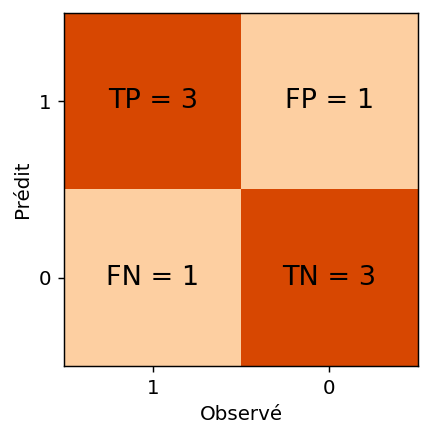

In [7]:
predicted = (scores >= 0.5).astype(int)
matrix = confusion_matrix(truth, predicted, labels=[1, 0]).T
fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.imshow(matrix, cmap="Oranges", vmin=0, vmax=4)
for row in range(2):
    for col in range(2):
        name = [["TP", "FP"], ["FN", "TN"]][row][col]
        ax.text(col, row, f"{name} = {matrix[row, col]}",
                ha="center", va="center", fontsize=15)
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=[1, 0], yticklabels=[1, 0],
       xlabel="Observé", ylabel="Prédit")
plt.tight_layout()
plt.show()

Au seuil 0.5, TP/FP/FN/TN = 3/1/1/3. Au seuil 0.8 : 2/0/2/4. L’exactitude reste à 0.75, le rappel passe de 0.75 à 0.5.

ROC et PR reçoivent les **scores de probabilité**, pas les classes seuillées. AP pondère la précision par les gains de rappel ; ce n’est pas l’aire PR par trapèzes.

ROC-AUC = 0.8750; AP = 0.8875


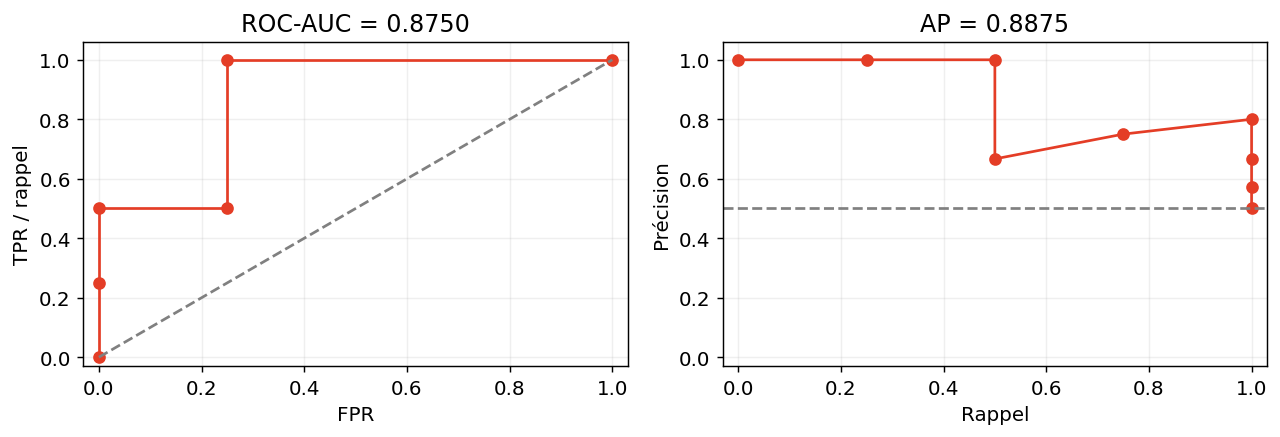

In [8]:
fpr, tpr, roc_thresholds = roc_curve(truth, scores)
precision, recall, pr_thresholds = precision_recall_curve(truth, scores)
auc = roc_auc_score(truth, scores)
ap = average_precision_score(truth, scores)
print(f"ROC-AUC = {auc:.4f}; AP = {ap:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(fpr, tpr, "o-", color="#e43d26")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="FPR", ylabel="TPR / rappel", title=f"ROC-AUC = {auc:.4f}")
axes[1].plot(recall, precision, "o-", color="#e43d26")
axes[1].axhline(np.mean(truth), linestyle="--", color="gray")
axes[1].set(xlabel="Rappel", ylabel="Précision",
            title=f"AP = {ap:.4f}")
for ax in axes:
    ax.set(xlim=(-0.03, 1.03), ylim=(-0.03, 1.06))
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
assert np.isclose(auc, 0.875) and np.isclose(ap, 0.8875)

**Vérifier :** ROC–AUC = 0.875 ; AP = 0.8875.

1. Quel positif supplémentaire est manqué lorsque le seuil augmente ?
2. ROC–AUC change-t-elle si seul ce seuil de décision change ?
3. Pourquoi une même exactitude peut-elle cacher des conséquences différentes ?

Poursuivre avec `02_Exercices_FR.ipynb`.

## Références
- [Stanford CS229 : apprentissage supervisé](https://see.stanford.edu/materials/aimlcs229/cs229-notes1.pdf)
- [scikit-learn : matrice de confusion](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [scikit-learn : précision–rappel](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)